<a href="https://colab.research.google.com/github/nguyenkyvi/Machine_Learning/blob/main/Lab09_MLB/Lab9_MLB.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import numpy as np


def sigmoid(z):
    return 1 / (1 + np.exp(-z))


def relu(z):
    return np.maximum(0, z)


# Phần 1: một nơ-ron với hàm sigmoid, chính là hồi quy logistic
w = np.array([0.8, -0.5, 0.3])
b = -0.2
x = np.array([2.0, 1.0, 3.0])
z = w @ x + b
print("Mot no-ron:")
print(f"  z = {w[0]}*{x[0]} + ({w[1]})*{x[1]} + {w[2]}*{x[2]}"
      f" + ({b}) = {z:.2f}")
print(f"  a = sigmoid(z) = {sigmoid(z):.4f}")
print()

# Phần 2: mạng 2 đầu vào, 2 nơ-ron ẩn ReLU, 1 nơ-ron ra
# Trọng số tự đặt để mạng tính đúng phép XOR
W1 = np.array([[1.0, 1.0],            # cột 1: trọng số vào nơ-ron ẩn h1
               [1.0, 1.0]])           # cột 2: trọng số vào nơ-ron ẩn h2
b1 = np.array([0.0, -1.0])
W2 = np.array([1.0, -2.0])
b2 = 0.0

X = np.array([[0, 0], [0, 1], [1, 0], [1, 1]], dtype=float)
print("Mang giai XOR:")
print("  x1  x2   h1  h2    y")
for x in X:
    h = relu(x @ W1 + b1)             # Lớp ẩn
    y = h @ W2 + b2                   # Lớp ra
    print(f"  {x[0]:.0f}   {x[1]:.0f}    {h[0]:.0f}   {h[1]:.0f}"
          f"    {y:.0f}")
print()

# Cả bốn đầu vào cùng lúc bằng phép nhân ma trận
H = relu(X @ W1 + b1)
Y = H @ W2 + b2
print("Tinh ca bang mot lan:", Y)

Mot no-ron:
  z = 0.8*2.0 + (-0.5)*1.0 + 0.3*3.0 + (-0.2) = 1.80
  a = sigmoid(z) = 0.8581

Mang giai XOR:
  x1  x2   h1  h2    y
  0   0    0   0    0
  0   1    1   0    1
  1   0    1   0    1
  1   1    2   1    0

Tinh ca bang mot lan: [0. 1. 1. 0.]


In [3]:
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier

df = pd.read_csv("data/xor.csv")
X = df[["x1", "x2"]]
y = df["nhan"]
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

lr = LogisticRegression().fit(X_tr, y_tr)
print(f"Hoi quy logistic: {accuracy_score(y_te, lr.predict(X_te)):.4f}")
print()

# Dữ liệu nhỏ nên dùng solver="lbfgs", học nhanh và ổn định hơn
print("So no-ron an   so tham so   tap hoc   tap kiem tra")
for so in [1, 2, 4, 8]:
    mlp = MLPClassifier(hidden_layer_sizes=(so,), solver="lbfgs",
                        max_iter=5000, random_state=0)
    mlp.fit(X_tr, y_tr)
    # coefs_ là danh sách ma trận trọng số, intercepts_ là hệ số chặn
    so_ts = sum(w.size for w in mlp.coefs_)
    so_ts += sum(b.size for b in mlp.intercepts_)
    a_hoc = accuracy_score(y_tr, mlp.predict(X_tr))
    a_kt = accuracy_score(y_te, mlp.predict(X_te))
    print(f"     {so:2d}           {so_ts:3d}       {a_hoc:.4f}"
          f"    {a_kt:.4f}")

Hoi quy logistic: 0.6300

So no-ron an   so tham so   tap hoc   tap kiem tra
      1             5       0.6700    0.6900
      2             9       0.7533    0.7800
      4            17       0.7733    0.8300
      8            33       0.9300    0.9300


In [4]:
import pandas as pd
from sklearn.metrics import accuracy_score
from sklearn.model_selection import cross_val_score, train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

df = pd.read_csv("data/hai_vang_trang.csv")
X = df[["x1", "x2"]]
y = df["nhan"]
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)


def mang(lop_an, alpha):
    return make_pipeline(
        StandardScaler(),
        MLPClassifier(hidden_layer_sizes=lop_an, alpha=alpha,
                      solver="lbfgs", max_iter=20000, random_state=0),
    )


print("Ba mang               tap hoc   tap kiem tra")
for ten, lop_an, alpha in [("(2,), alpha 1e-4", (2,), 1e-4),
                           ("(100, 100), 1e-5", (100, 100), 1e-5),
                           ("(100, 100), 1.0", (100, 100), 1.0)]:
    m = mang(lop_an, alpha).fit(X_tr, y_tr)
    print(f"  {ten:18s} {accuracy_score(y_tr, m.predict(X_tr)):.4f}"
          f"    {accuracy_score(y_te, m.predict(X_te)):.4f}")
print()

# Chọn alpha bằng kiểm định chéo, chỉ trên tập học
print("alpha      kiem dinh cheo")
diem = {}
for alpha in [1e-5, 1e-3, 0.1, 1.0, 3.0, 10.0]:
    diem[alpha] = cross_val_score(mang((100, 100), alpha),
                                  X_tr, y_tr, cv=5).mean()
    print(f"  {alpha:<8}  {diem[alpha]:.4f}")

a_tot = max(diem, key=diem.get)
m = mang((100, 100), a_tot).fit(X_tr, y_tr)
print(f"alpha tot nhat = {a_tot}, tap kiem tra "
      f"{accuracy_score(y_te, m.predict(X_te)):.4f}")

Ba mang               tap hoc   tap kiem tra
  (2,), alpha 1e-4   0.8444    0.8533
  (100, 100), 1e-5   1.0000    0.7733
  (100, 100), 1.0    0.8844    0.9067

alpha      kiem dinh cheo
  1e-05     0.7822
  0.001     0.7822
  0.1       0.7689
  1.0       0.8578
  3.0       0.8400
  10.0      0.8356
alpha tot nhat = 1.0, tap kiem tra 0.9067


In [5]:
import pandas as pd
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

df = pd.read_csv("data/sinh_vien_mo_rong.csv")
X = df[["gio_on", "diem_giua_ky", "chi_tieu"]]
y = df["qua_mon"]
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

tho = MLPClassifier(hidden_layer_sizes=(20,), max_iter=3000,
                    random_state=0).fit(X_tr, y_tr)
chuan = make_pipeline(
    StandardScaler(),
    MLPClassifier(hidden_layer_sizes=(20,), max_iter=3000,
                  random_state=0),
).fit(X_tr, y_tr)

print(f"Doan bua ca lop qua : {y_te.mean():.4f}")
print(f"Khong chuan hoa     : "
      f"{accuracy_score(y_te, tho.predict(X_te)):.4f}")
print(f"Co chuan hoa        : "
      f"{accuracy_score(y_te, chuan.predict(X_te)):.4f}")
print()

# Mạng không chuẩn hoá đoán ra sao
du = tho.predict(X_te)
print("Khong chuan hoa, so ban doan qua:", du.sum(), "tren", len(du))

Doan bua ca lop qua : 0.6000
Khong chuan hoa     : 0.4000
Co chuan hoa        : 0.9000

Khong chuan hoa, so ban doan qua: 0 tren 30


In [6]:
import numpy as np
from sklearn.datasets import load_digits
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

X, y = load_digits(return_X_y=True)
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

mang = make_pipeline(
    StandardScaler(),
    MLPClassifier(hidden_layer_sizes=(100,), max_iter=1000,
                  random_state=0),
).fit(X_tr, y_tr)
mlp = mang[-1]

print("Kich thuoc cac ma tran trong so:",
      [w.shape for w in mlp.coefs_])
so_ts = sum(w.size for w in mlp.coefs_)
so_ts += sum(b.size for b in mlp.intercepts_)
print("Tong so tham so:", so_ts)
print("So vong hoc:", mlp.n_iter_)
mm = mlp.loss_curve_
print(f"Mat mat vong 1: {mm[0]:.4f}, vong 10: {mm[9]:.4f},"
      f" vong cuoi: {mm[-1]:.4f}")
print()

du = mang.predict(X_te)
print(f"Accuracy tren tap kiem tra: {accuracy_score(y_te, du):.4f}")
sai = np.flatnonzero(du != y_te)
print("So anh doan sai:", len(sai), "tren", len(y_te))
for i in sai:
    print(f"  anh {i:3d}: that la {y_te[i]}, doan la {du[i]}")
print()

# Dừng sớm: giữ riêng 10% tập học để theo dõi
dung_som = make_pipeline(
    StandardScaler(),
    MLPClassifier(hidden_layer_sizes=(100,), max_iter=1000,
                  early_stopping=True, random_state=0),
).fit(X_tr, y_tr)
print("Dung som sau:", dung_som[-1].n_iter_, "vong, accuracy",
      f"{accuracy_score(y_te, dung_som.predict(X_te)):.4f}")
print()

# So với các mô hình đã học, cùng tập học và tập kiểm tra
khac = {
    "Logistic co chuan hoa": make_pipeline(
        StandardScaler(), LogisticRegression(max_iter=2000)),
    "KNN, k = 5": KNeighborsClassifier(),
    "SVM kernel RBF": SVC(),
}
for ten, mh in khac.items():
    acc = accuracy_score(y_te, mh.fit(X_tr, y_tr).predict(X_te))
    print(f"{ten:22s} {acc:.4f}")

Kich thuoc cac ma tran trong so: [(64, 100), (100, 10)]
Tong so tham so: 7510
So vong hoc: 144
Mat mat vong 1: 2.5206, vong 10: 0.4448, vong cuoi: 0.0052

Accuracy tren tap kiem tra: 0.9844
So anh doan sai: 7 tren 450
  anh   6: that la 9, doan la 3
  anh  61: that la 5, doan la 7
  anh  77: that la 2, doan la 1
  anh  85: that la 9, doan la 7
  anh 276: that la 8, doan la 2
  anh 428: that la 7, doan la 9
  anh 443: that la 4, doan la 7

Dung som sau: 44 vong, accuracy 0.9578

Logistic co chuan hoa  0.9711
KNN, k = 5             0.9867
SVM kernel RBF         0.9911


BÀI TẬP

BÀI 1

In [7]:
import numpy as np, pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier

df = pd.read_csv("data/xor.csv")
X = df[["x1", "x2"]]
y = df["nhan"]
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25, random_state=17, stratify=y)

mlp = MLPClassifier(hidden_layer_sizes=(8,), solver="lbfgs", max_iter=5000, random_state=0)
mlp.fit(X_tr, y_tr)

def relu(z):
    return np.maximum(0, z)

def sigmoid(z):
    return 1 / (1 + np.exp(-z))

W1, W2 = mlp.coefs_
b1, b2 = mlp.intercepts_
x5 = X_te.to_numpy()[:5]

h = relu(x5 @ W1 + b1)            # lop an: ReLU
p_tay = sigmoid(h @ W2 + b2)      # lop ra: sigmoid
p_thu_vien = mlp.predict_proba(X_te)[:5, 1]

print("Diem   tu tinh        predict_proba     lech")
for i in range(5):
    print(f"  {i}   {p_tay[i, 0]:.10f}   {p_thu_vien[i]:.10f}   {abs(p_tay[i, 0] - p_thu_vien[i]):.2e}")
print("Khop toi 10 chu so thap phan:", np.allclose(p_tay[:, 0], p_thu_vien, atol=1e-10))

Diem   tu tinh        predict_proba     lech
  0   0.0408230610   0.0408230610   0.00e+00
  1   0.9687374547   0.9687374547   0.00e+00
  2   0.9202237673   0.9202237673   0.00e+00
  3   0.9990891994   0.9990891994   0.00e+00
  4   0.0494380182   0.0494380182   0.00e+00
Khop toi 10 chu so thap phan: True


bài 2

In [8]:
import numpy as np

def relu(z):
    return np.maximum(0, z)

X = np.array([[0, 0], [0, 1], [1, 0], [1, 1]], dtype=float)
h1 = relu(X[:, 0] - X[:, 1])
h2 = relu(X[:, 1] - X[:, 0])
y = h1 + h2
print(" x1  x2   h1  h2   y")
for i in range(4):
    print(f"  {X[i,0]:.0f}   {X[i,1]:.0f}    {h1[i]:.0f}   {h2[i]:.0f}   {y[i]:.0f}")
print("Khop XOR:", np.array_equal(y, [0, 1, 1, 0]))

 x1  x2   h1  h2   y
  0   0    0   0   0
  0   1    0   1   1
  1   0    1   0   1
  1   1    0   0   0
Khop XOR: True


Bài 3


In [9]:
import warnings; warnings.filterwarnings("ignore")
import pandas as pd
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

df = pd.read_csv("data/hai_vang_trang.csv")
X, y = df[["x1", "x2"]], df["nhan"]
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25, random_state=17, stratify=y)

print("Ham kich hoat   tap hoc   tap kiem tra")
for act in ["logistic", "tanh", "relu"]:
    m = make_pipeline(StandardScaler(),
                      MLPClassifier(hidden_layer_sizes=(100, 100), alpha=1.0, activation=act,
                                    solver="lbfgs", max_iter=20000, random_state=0)).fit(X_tr, y_tr)
    print(f"  {act:12s}  {accuracy_score(y_tr, m.predict(X_tr)):.4f}    {accuracy_score(y_te, m.predict(X_te)):.4f}")

Ham kich hoat   tap hoc   tap kiem tra
  logistic      0.8400    0.8533
  tanh          0.8711    0.9067
  relu          0.8844    0.9067


Bài 4

learning_rate_init  so vong  mat mat cuoi  accuracy kiem tra
  0.0001                582   0.0189       0.9889
  0.001                 144   0.0052       0.9844
  0.01                   38   0.0011       0.9778
  0.1                    30   0.1230       0.9667


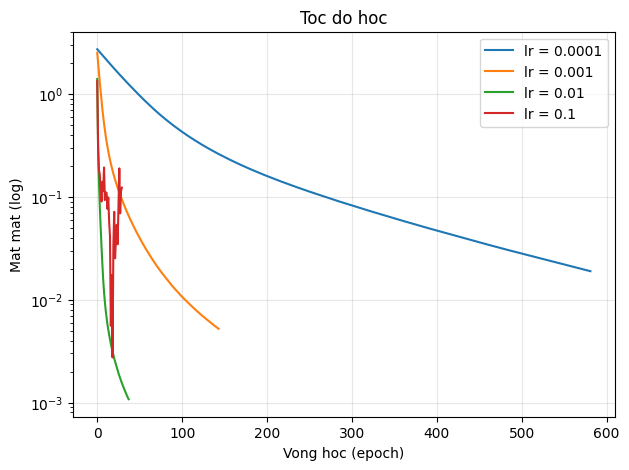

In [10]:
import warnings; warnings.filterwarnings("ignore")
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

X, y = load_digits(return_X_y=True)
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25, random_state=17, stratify=y)

plt.figure(figsize=(7, 5))
print("learning_rate_init  so vong  mat mat cuoi  accuracy kiem tra")
for lr in [0.0001, 0.001, 0.01, 0.1]:
    m = make_pipeline(StandardScaler(),
                      MLPClassifier(hidden_layer_sizes=(100,), learning_rate_init=lr,
                                    max_iter=1000, random_state=0)).fit(X_tr, y_tr)
    mlp = m[-1]
    print(f"  {lr:<17}  {mlp.n_iter_:6d}   {mlp.loss_curve_[-1]:.4f}       {accuracy_score(y_te, m.predict(X_te)):.4f}")
    plt.plot(mlp.loss_curve_, label=f"lr = {lr}")
plt.yscale("log")
plt.xlabel("Vong hoc (epoch)")
plt.ylabel("Mat mat (log)")
plt.title("Toc do hoc")
plt.legend()
plt.grid(alpha=0.3)
plt.savefig("toc_do_hoc.png", dpi=150, bbox_inches="tight")
plt.show()

Bài 5

In [11]:
import warnings; warnings.filterwarnings("ignore")
from sklearn.datasets import load_digits
from sklearn.metrics import accuracy_score
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

X, y = load_digits(return_X_y=True)
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25, random_state=17, stratify=y)

pipe = make_pipeline(StandardScaler(), MLPClassifier(max_iter=1000, random_state=0))
luoi = {"mlpclassifier__hidden_layer_sizes": [(10,), (50,), (100,), (50, 50)],
        "mlpclassifier__alpha": [0.0001, 0.01, 1]}
gs = GridSearchCV(pipe, luoi, cv=5, n_jobs=-1).fit(X_tr, y_tr)
print("Cap tot nhat:", gs.best_params_)
print(f"Kiem dinh cheo: {gs.best_score_:.4f}")
print(f"Tap kiem tra  : {accuracy_score(y_te, gs.predict(X_te)):.4f}")
svm = SVC().fit(X_tr, y_tr)
print(f"SVM (bai 6)   : {accuracy_score(y_te, svm.predict(X_te)):.4f}")

Cap tot nhat: {'mlpclassifier__alpha': 1, 'mlpclassifier__hidden_layer_sizes': (50,)}
Kiem dinh cheo: 0.9785
Tap kiem tra  : 0.9822
SVM (bai 6)   : 0.9911


Bài 6

In [12]:
import warnings; warnings.filterwarnings("ignore")
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

df = pd.read_csv("data/gia_nha.csv")
X, y = df.drop(columns="gia"), df["gia"]
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25, random_state=17)

tt = LinearRegression().fit(X_tr, y_tr)
nn = make_pipeline(StandardScaler(), MLPRegressor(hidden_layer_sizes=(20,), max_iter=5000, random_state=0)).fit(X_tr, y_tr)
print(f"MAE hoi quy tuyen tinh: {mean_absolute_error(y_te, tt.predict(X_te)):.4f}")
print(f"MAE mang no-ron       : {mean_absolute_error(y_te, nn.predict(X_te)):.4f}")

can = pd.DataFrame({"dien_tich": [250.0], "so_phong": [X["so_phong"].median()], "tuoi_nha": [X["tuoi_nha"].median()]})
print("Dien tich lon nhat trong du lieu:", X["dien_tich"].max())
print(f"Du doan can 250 m2 (so_phong={can.so_phong[0]}, tuoi_nha={can.tuoi_nha[0]}):")
print(f"  tuyen tinh: {tt.predict(can)[0]:.2f} ty")
print(f"  no-ron    : {nn.predict(can)[0]:.2f} ty")

MAE hoi quy tuyen tinh: 0.2185
MAE mang no-ron       : 0.4242
Dien tich lon nhat trong du lieu: 117.5
Du doan can 250 m2 (so_phong=2.0, tuoi_nha=13.5):
  tuyen tinh: 18.48 ty
  no-ron    : 20.91 ty
